# Ancient Environmental Metagenomics (AEMG01)
## Day 5 · Part 1: aMeta – an accurate and memory-efficient ancient metagenomic profiling workflow

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day5_aMeta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Prerequisite:** `Day1_setup.ipynb` (`course_paths.json`).

During Days 1–4 we ran every step by hand: trimming, taxonomic profiling, filtering on depth and breadth, alignment, authentication. In this practical we meet **aMeta**, which automates all of these steps as one reproducible workflow (Pochon et al. 2023).

### What we do today
* **Run:** install aMeta and run its **built-in test** on a tiny dataset – a complete run of the workflow, from raw reads to the authentication heatmap, that fits in Colab.
* **Read and understand (not run):** how aMeta is configured and run on real data – databases, configuration files, memory tuning, outputs. A real run needs far more memory than Colab offers (the MALT step alone was tuned to 96 GB), so those commands are explained but **not meant to be run here**.

### Learning outcomes
* explain the design of aMeta: **KrakenUniq screening + MALT/Bowtie2 alignment + authentication**, and why it saves memory,
* explain how a **Snakemake** workflow is organised (rules, DAG, per-rule conda environments),
* install aMeta and run its test,
* configure aMeta for your own data (`samples.tsv`, `config.yaml`),
* interpret aMeta's **authentication scores** and the **seven quality metrics** behind them.

---
## Scientific background: why a workflow, and why aMeta?

Everything aMeta does, you have already done by hand this week:

| aMeta step | Where you did it by hand |
|---|---|
| FastQC, Cutadapt adapter trimming, MultiQC | Day 1 |
| **KrakenUniq** classification against a large database | Day 2 |
| filtering on **depth (taxReads ≥ 200)** and **breadth (unique k-mers ≥ 1000)** | Day 2 |
| alignment of reads to the detected organisms; evenness of coverage, edit distance | Day 3 |
| **deamination**, read length, **PMD scores** | Day 3 |
| combining all evidence into one decision | Day 3, Section 6 |

Doing this for dozens of samples and hundreds of candidate organisms by hand is slow and error-prone. A **workflow manager** runs all steps in the right order, in parallel, with a fixed software environment, and re-runs only what has changed – which makes the analysis **reproducible**.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/aMeta.png" width="760"><br><em>The aMeta workflow (Pochon et al. 2023).</em></p>

**The design of aMeta** combines the strengths of k-mer classification and alignment:

1. **Detection with KrakenUniq.** Reads are classified against a very large database (e.g. all complete microbial NCBI RefSeq genomes). KrakenUniq is fast and – thanks to the unique k-mer filter – produces few false positives.
2. **Alignment only where needed.** Instead of aligning every read to every genome (which would need hundreds of GB of RAM for a large database), aMeta builds a **MALT** database containing only the species KrakenUniq has detected in the samples. MALT is an aligner with an LCA algorithm (as in MEGAN); with this small, project-specific database, alignment becomes affordable. In parallel, reads are aligned with **Bowtie2** to a pre-built index of **pathogen** genomes.
3. **Authentication.** For every detected organism in every sample, aMeta computes the metrics from Day 3 (deamination, evenness of coverage, edit distance of all and of damaged reads, read length, PMD scores, depth) and combines them into an **authentication score from 0 to 10**.

This is what makes aMeta both **accurate** (low false-positive rate from the k-mer filter, plus alignment-based authentication) and **memory-efficient** (the alignment database is small). In the aMeta paper, this combination reduced false-positive detections on simulated data while needing far less memory than alignment against a MALT database of all genomes.

### Snakemake in one picture
aMeta is written in [**Snakemake**](https://snakemake.readthedocs.io/), the most widely used workflow manager in bioinformatics.

<p align="center">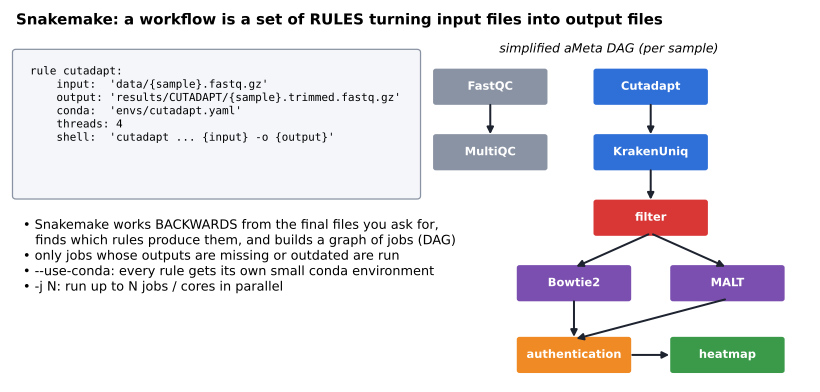</p>

A Snakemake workflow consists of **rules**. Each rule says which **input** files it needs, which **output** files it produces, which **conda environment** it uses, and which **shell command** turns one into the other. `{sample}` is a *wildcard*: one rule is applied to every sample. When you ask for the final results, Snakemake works backwards, figures out which jobs are needed, arranges them in a **directed acyclic graph (DAG)** and runs them – in parallel where possible, and only if their outputs are missing or older than their inputs.

---
## 1. Session setup

### 1.1 Install conda
`condacolab.install()` restarts the kernel – the *"session crashed"* message is expected; continue with the next cell.

In [1]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:20
🔁 Restarting kernel...


In [1]:
import shutil, sys
mamba = shutil.which("mamba")
print("Python :", sys.executable)
print("mamba  :", mamba or "NOT FOUND")
assert mamba, "conda/mamba is not installed – run the condacolab.install() cell above and wait for the restart"
!mamba --version

Python : /usr/bin/python3.real
mamba  : /usr/local/bin/mamba
2.5.0


### 1.2 Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.3 Paths and helpers

* `AMETA` – where we clone aMeta: on the **local Colab disk** (`/content/aMeta`), because files on Drive cannot be executed and the workflow writes many small files (much faster locally),
* `RES` – folder in your Drive where we keep the test results (`12_AMETA`),
* `ENVS` – the conda environments folder.

`show_file()` displays the PDF and HTML reports produced by aMeta inside the notebook.

In [3]:
import os, json, glob, subprocess, socket, time
from google.colab import output, files
from IPython.display import HTML, Image, display, Markdown

WORKDIR = "/content/drive/MyDrive/AncientEnvironmentalMetagenomics"
SHARE = json.load(open(f"{WORKDIR}/course_paths.json"))["SHARE"]
AMETA = "/content/aMeta"
RES = f"{WORKDIR}/12_AMETA"
ENVS = subprocess.run(["conda", "info", "--base"], capture_output=True, text=True).stdout.strip() + "/envs"
os.makedirs(RES, exist_ok=True)
os.environ.update(WORKDIR=WORKDIR, SHARE=SHARE, AMETA=AMETA, RES=RES, ENVS=ENVS,
                  THREADS=str(os.cpu_count()), MPLBACKEND="Agg")

PORT = 8000
def _server_running(port=PORT):
    with socket.socket() as s:
        return s.connect_ex(("localhost", port)) == 0

def show_file(path, height=700):
    """Show an HTML or PDF file (absolute path under /content) in an embedded frame."""
    if not _server_running():
        subprocess.Popen(["python", "-m", "http.server", str(PORT), "--directory", "/content"],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        time.sleep(2)
    output.serve_kernel_port_as_iframe(PORT, path="/" + os.path.relpath(path, "/content"), height=height)

for k in ["SHARE", "AMETA", "RES", "ENVS", "THREADS"]:
    print(f"{k:8s}: {os.environ[k]}")

SHARE   : /content/drive/MyDrive/AncientEnvironmentalMetagenomics
AMETA   : /content/aMeta
RES     : /content/drive/MyDrive/AncientEnvironmentalMetagenomics/12_AMETA
ENVS    : /usr/local/envs
THREADS : 2


---
## 2. Install aMeta

### 2.1 Get the code
aMeta is developed on GitHub by NBIS (National Bioinformatics Infrastructure Sweden). `git clone` downloads the repository. Let's look at how it is organised:

| Folder / file | Content |
|---|---|
| `workflow/Snakefile` | the main workflow file; it includes the rule files |
| `workflow/rules/*.smk` | the rules, grouped by topic (QC, KrakenUniq, MALT, authentication, …) |
| `workflow/envs/*.yaml` | one conda environment per group of tools (used with `--use-conda`) |
| `workflow/envs/environment.yaml` | the **main** environment: Snakemake itself and a few helpers |
| `workflow/scripts/` | helper scripts (Python, R, bash) called by the rules |
| `config/` | where `samples.tsv` and `config.yaml` for your own project go |
| `.test/` | a tiny test dataset with its own configuration and the script `runtest.sh` |

In [4]:
%%bash
cd /content
[ -d aMeta ] || git clone -q https://github.com/NBISweden/aMeta
cd aMeta
git log --oneline -1
ls
echo; echo "== rule files ==";      ls workflow/rules
echo; echo "== conda environments =="; ls workflow/envs

d8cc33b Merge pull request #211 from NBISweden/preload-size
conda-linux-64.v7.lock
conda-linux-64.v8.lock
config
images
LICENSE
misc
profile
README.md
resources
vignettes
workflow

== rule files ==
align.smk
authentic.smk
common.smk
config.py
damage.smk
krakenuniq.smk
malt.smk
qc.smk
summary.smk

== conda environments ==
bowtie2.yaml
cutadapt.yaml
environment.v8.yaml
environment.yaml
fastqc.yaml
krakenuniq.yaml
krona.yaml
malt.yaml
mapdamage.yaml
multiqc_config.yaml
multiqc.yaml
r.yaml
samtools.yaml


### 2.2 Create the main aMeta environment

The main environment contains **Snakemake** and the tools it needs to manage the other environments. In the course text this is the commented line `conda env create -f workflow/envs/environment.yaml`; here we use the faster `mamba` and name the environment `aMeta` (`-n aMeta`). Let's first look at what it contains – note the pinned Snakemake version: workflows are tied to the Snakemake version they were written for.

Creating the environment takes 5–10 minutes; the log goes to `/content/install_ameta.log`.

In [5]:
%%bash
cd "${AMETA:?AMETA is not set - run cell 1.3 first}"
cat workflow/envs/environment.yaml
mamba env create -n aMeta -f workflow/envs/environment.yaml > /content/install_ameta.log 2>&1
echo; echo "Snakemake in the aMeta environment: $(PATH=$ENVS/aMeta/bin:$PATH snakemake --version)"

name: aMeta

channels:
  - conda-forge
  - bioconda

dependencies:
  # core packages for workflow
  - python>=3.10,<3.12
  - snakemake-minimal>=6.0,<8
  - mamba
  - setuptools<81
  - pandas
  - biopython
  - fastqc>=0.12.1
  - mapdamage2
  - multiqc
  - bowtie2
  - samtools
  - cutadapt
  - krakenuniq
  - krona
  - r-base
  - hops
  - seqtk
  - parallel
  - megan
  - r-pheatmap
  - pmdtools
  - pysam

  # packages required to create snakemake reports
  - pygments
  - jinja2
  - networkx
  - pygraphviz
  - imagemagick<8
  - graphviz
  - pandoc

Snakemake in the aMeta environment: 7.32.4


As on previous days, instead of `conda activate aMeta` (which does not carry over between notebook cells) we put the environment's `bin` folder first on the `PATH` for each command: `PATH=$ENVS/aMeta/bin:$PATH snakemake …`.

---
## 3. Run the aMeta test

To ensure that aMeta has been correctly installed, we run its **test**. The test data are a few small FASTQ files and tiny databases (KrakenUniq, Bowtie2, MALT) built for a handful of genomes, so that **every rule of the workflow** runs – just on very little data. Let's first read what the test script does:

In [6]:
%%bash
cd "${AMETA:?AMETA is not set - run cell 1.3 first}/.test"
cat runtest.sh
echo; echo "== test folder =="; ls

set -e # <- exit immediately on failure
conda_version=$(conda --version | awk '{print $2}')
conda_major=$(echo $conda_version | awk -F. '{print $1}')
conda_minor=$(echo $conda_version | awk -F. '{print $2}')

if [[ $conda_major -lt 23 ]] || [[ $conda_major -lt 24 && $conda_minor -lt 10 ]]; then
    CONDA_FRONTEND_DEFAULT=mamba
else
    CONDA_FRONTEND_DEFAULT=conda
fi

CONDA_FRONTEND="${CONDA_FRONTEND:=${CONDA_FRONTEND_DEFAULT}}"
echo "Conda version ${conda_version}: using conda frontend $CONDA_FRONTEND"

if [[ -z "$@" ]]; then
    echo "No snakemake options supplied. To run the tests, at least set the number of threads (e.g. -j 1)"
    echo "Example usage: "
    echo
    echo "./runtest.sh -j 1"
    echo
    echo "UPDATE: Starting from conda version 23.10.0, by default conda uses the libmamba-solver."
    echo "If you have an older conda version, consider running"
    echo
    echo "CONDA_FRONTEND=mamba ./runtest.sh -j 1"
    echo
    exit
fi
# check if we are running CI; if not, initi

`runtest.sh` sets up the test databases and configuration and then calls **Snakemake** with `--use-conda`. Arguments given to `runtest.sh` (here `-j`) are passed on to Snakemake:

* `-j $THREADS` – run up to `$THREADS` jobs (cores) in parallel (the course text uses `-j 1`; Colab has 2 cores),
* `--use-conda` – Snakemake creates the small conda environment of each rule the first time it is needed.

⏱️ **This takes a while (typically 30–60 minutes)**: most of the time is spent creating the ~10 rule environments (KrakenUniq, Bowtie2, MALT, mapDamage, Krona, …); the analysis itself takes minutes. The last 40 lines of the output are shown; the full log is in `/content/ameta_test.log`. If the Colab session disconnects, just re-run the cell – Snakemake continues where it stopped.

In [8]:
%%bash
cd "${AMETA:?AMETA is not set - run cell 1.3 first}/.test"
# make this shell look like an initialised conda shell, as runtest.sh expects
export CONDA_EXE=$(which conda)
export CONDA_PREFIX=$(conda info --base)
source $CONDA_PREFIX/etc/profile.d/conda.sh

PATH=$ENVS/aMeta/bin:$PATH ./runtest.sh -j $THREADS > /content/ameta_test.log 2>&1
status=$?
tail -n 40 /content/ameta_test.log
echo; [ $status -eq 0 ] && echo "✅ aMeta test finished successfully" || echo "❌ test failed (exit code $status) – see /content/ameta_test.log"

Failed to extract ref_id from results/AUTHENTICATION/foo/42862/MaltExtract_output/default/readDist/foo.trimmed.rma6_additionalNodeEntries.txt; returning taxid 42862
Failed to extract ref_id from results/AUTHENTICATION/foo/42862/MaltExtract_output/default/readDist/foo.trimmed.rma6_additionalNodeEntries.txt; returning taxid 42862
Select jobs to execute...

[Mon Nov 23 11:20:35 2026]
rule aggregate:
    input: results/AUTHENTICATION/foo/42862/MaltExtract_output/log.txt, results/AUTHENTICATION/foo/632/MaltExtract_output/log.txt, results/AUTHENTICATION/foo/632/PMD_plot.frag.pdf, results/AUTHENTICATION/foo/632/authentic_Sample_foo.trimmed.rma6_TaxID_632.pdf, results/AUTHENTICATION/foo/632/MaltExtract_output/analysis.RData, results/AUTHENTICATION/foo/632/authentication_scores.txt
    output: results/AUTHENTICATION/.foo_done
    log: logs/AGGREGATE/foo.log
    jobid: 27
    reason: Updated input files: results/AUTHENTICATION/foo/42862/MaltExtract_output/log.txt
    wildcards: sample=foo
    re

At the end, Snakemake prints a summary such as *"N of N steps (100%) done"*. Every line `rule <name>:` in the log is one job that was run; you can count how many jobs of each rule were executed:

In [9]:
%%bash
grep -oE "^(local)?rule [A-Za-z0-9_]+" /content/ameta_test.log | sort | uniq -c | sort -k1,1nr

      3 rule aggregate
      3 rule Make_Node_List
      2 localrule all
      1 rule Bowtie2_Index
      1 rule NCBIMapTre


### 3.1 Explore the test results

All outputs are in `.test/results/`, one folder per step – compare the folder names with the rules above.

In [10]:
%%bash
cd "${AMETA:?AMETA is not set - run cell 1.3 first}/.test/results" && ls
echo; echo "== PDF and HTML reports =="
find . \( -name "*.pdf" -o -name "*.html" \) | sort | head -n 40

AUTHENTICATION
AUTHENTICATION_PLOTS_PDF
AUTHENTICATION_PLOTS_PNG
BOWTIE2
CUTADAPT_ADAPTER_TRIMMING
FASTQC_AFTER_TRIMMING
FASTQC_BEFORE_TRIMMING
KRAKENUNIQ
KRAKENUNIQ_ABUNDANCE_MATRIX
MALT
MALT_ABUNDANCE_MATRIX_RMA6
MALT_ABUNDANCE_MATRIX_SAM
MALT_DB
MALT_QUANTIFY_ABUNDANCE
MAPDAMAGE
MULTIQC
overview_heatmap_scores.pdf
overview_heatmap_scores.txt

== PDF and HTML reports ==
./AUTHENTICATION/bar/632/authentic_Sample_bar.trimmed.rma6_TaxID_632.pdf
./AUTHENTICATION/bar/632/MaltExtract_output/heatmap_overview_Wevid.pdf
./AUTHENTICATION/bar/632/MaltExtract_output/pdf_candidate_profiles/Yersinia_pestis/stp2_bar.trimmed.rma6_Yersinia_pestis_summary.pdf
./AUTHENTICATION/bar/632/PMD_plot.frag.pdf
./AUTHENTICATION/foo/632/authentic_Sample_foo.trimmed.rma6_TaxID_632.pdf
./AUTHENTICATION/foo/632/MaltExtract_output/heatmap_overview_Wevid.pdf
./AUTHENTICATION/foo/632/MaltExtract_output/pdf_candidate_profiles/Yersinia_pestis/stp2_foo.trimmed.rma6_Yersinia_pestis_summary.pdf
./AUTHENTICATION/foo/632/PMD

The **overview heatmap** summarises the whole run: detected organisms (rows) × samples (columns), coloured by authentication score.

In [11]:
res = f"{AMETA}/.test/results"
heat = sorted(glob.glob(f"{res}/**/overview_heatmap_scores*.pdf", recursive=True))
if heat:
    print(heat[0]); show_file(heat[0], height=600)
else:
    print("No overview heatmap found – check that the test finished successfully.")

/content/aMeta/.test/results/overview_heatmap_scores.pdf


<IPython.core.display.Javascript object>

For every organism in every sample, aMeta also writes a page with the **seven quality metrics** in `results/AUTHENTICATION/<sample>/<taxID>/`. Let's open the first one:

In [13]:
auth = sorted(glob.glob(f"{res}/AUTHENTICATION/**/authentic_*.pdf", recursive=True))
print(f"{len(auth)} authentication reports")
for f in auth[:10]:
    print(" ", os.path.relpath(f, res))
if auth:
    show_file(auth[0], height=650)

2 authentication reports
  AUTHENTICATION/bar/632/authentic_Sample_bar.trimmed.rma6_TaxID_632.pdf
  AUTHENTICATION/foo/632/authentic_Sample_foo.trimmed.rma6_TaxID_632.pdf


<IPython.core.display.Javascript object>

Any HTML report of the run (e.g. MultiQC, Krona) can be opened the same way:

In [14]:
htmls = sorted(glob.glob(f"{res}/**/*.html", recursive=True))
for i, f in enumerate(htmls):
    print(i, os.path.relpath(f, res))
if htmls:
    show_file(htmls[0], height=650)     # change the index to open another report

0 FASTQC_AFTER_TRIMMING/bar.trimmed_fastqc.html
1 FASTQC_AFTER_TRIMMING/foo.trimmed_fastqc.html
2 FASTQC_BEFORE_TRIMMING/bar_fastqc.html
3 FASTQC_BEFORE_TRIMMING/foo_fastqc.html
4 KRAKENUNIQ/bar/taxonomy.krona.html
5 KRAKENUNIQ/foo/taxonomy.krona.html
6 MULTIQC/multiqc_report.html


<IPython.core.display.Javascript object>

Save the reports to your Drive (the local Colab disk is wiped when the session ends). We copy only PDF, HTML and text tables, keeping the folder structure:

In [15]:
import shutil
n = 0
for f in glob.glob(f"{res}/**/*", recursive=True):
    if f.endswith((".pdf", ".html", ".txt", ".tsv")):
        dest = os.path.join(RES, "test_results", os.path.relpath(f, res))
        os.makedirs(os.path.dirname(dest), exist_ok=True)
        shutil.copy2(f, dest); n += 1
print(f"copied {n} files to {RES}/test_results")

copied 179 files to /content/drive/MyDrive/AncientEnvironmentalMetagenomics/12_AMETA/test_results


❓ **Questions**
1. Which rules ran most often, and why (think about wildcards)?
2. Which organisms were detected in the test data, and what are their authentication scores?
3. Open an authentication PDF: which of the seven metrics support the organism being ancient, and which don't?

---
## 4. Running aMeta on real data – explained, not run

> ⚠️ **The commands in this section are not meant to be run in Colab.** They show how you would run aMeta on the 10 course samples on a server or HPC cluster. The KrakenUniq database alone needs to be loaded into memory, and MALT was configured with up to 96 GB of Java heap – far beyond Colab's ~12 GB. They are shown as text (not code cells) for that reason.

### 4.1 Data, databases and indexes

**The data.** For demonstration, aMeta was benchmarked on the same 10 samples simulated with [gargammel](https://academic.oup.com/bioinformatics/article/33/4/577/2608651) that we have used all week (available at [doi:10.17044/scilifelab.21261405](https://doi.org/10.17044/scilifelab.21261405)). They go into a `data` folder inside aMeta:

```bash
cd aMeta
cp -r $SHARE/data .

# In case you want to download the data, they are available here:
#wget https://figshare.scilifelab.se/ndownloader/articles/21261405/versions/1 \
#&& export UNZIP_DISABLE_ZIPBOMB_DETECTION=true && unzip 1 && rm 1
```

`export UNZIP_DISABLE_ZIPBOMB_DETECTION=true` – very large zip archives can trigger `unzip`'s "zip bomb" protection; this variable switches the check off for this trusted download.

**The KrakenUniq database** – the same pre-built database of complete microbial NCBI RefSeq genomes you used on Day 2 (in the course it is already in `$SHARE/Databases/KrakenUniq_DB`):

```bash
cd aMeta/resources
cp -r $SHARE/Databases/KrakenUniq_DB .

# In case you want to download the database, it is available here:
#wget https://figshare.scilifelab.se/ndownloader/articles/21299541/versions/1 \
#&& export UNZIP_DISABLE_ZIPBOMB_DETECTION=true && unzip 1 && rm 1
```

**The Bowtie2 index** of the **pathogen** genomes of the KrakenUniq database (used to align reads of detected pathogens):

```bash
cd aMeta/resources
cp -r $SHARE/Databases/Bowtie2_index .

# In case you want to download the Bowtie2 index, it is available here:
#wget https://figshare.scilifelab.se/ndownloader/articles/21185887/versions/1 \
#&& export UNZIP_DISABLE_ZIPBOMB_DETECTION=true && unzip 1 && rm 1
```

**Helper files with NCBI taxonomy information** for building the project-specific MALT database:

```bash
cd aMeta/resources
cp $SHARE/seqid2taxid.map.orig .          # sequence ID  -> taxonomy ID of every genome in the database
cp $SHARE/nucl_gb.accession2taxid .       # NCBI accession -> taxonomy ID (used by MALT)
cp $SHARE/library.fna .                   # all genome sequences of the database (FASTA)
#wget https://figshare.scilifelab.se/ndownloader/files/38201982 && mv 38201982 seqid2taxid.map.orig
#wget https://figshare.scilifelab.se/ndownloader/files/38201937 && mv 38201937 nucl_gb.accession2taxid
#wget https://figshare.scilifelab.se/ndownloader/files/37395181 && mv 37395181 library.fna.gz && gunzip library.fna.gz
```

`library.fna` is the reason aMeta can build a *small* MALT database: after KrakenUniq has detected species in your samples, aMeta extracts **only those species' genomes** from `library.fna` and builds the MALT index from them.

### 4.2 Configuration

aMeta is configured with two files in `aMeta/config/`.

**`samples.tsv`** – a tab-delimited table with one line per sample: the sample name (used in all output file names) and the path to its FASTQ file:

```
sample  fastq
sample1 data/sample1.fastq.gz
sample2 data/sample2.fastq.gz
sample3 data/sample3.fastq.gz
sample4 data/sample4.fastq.gz
sample5 data/sample5.fastq.gz
sample6 data/sample6.fastq.gz
sample7 data/sample7.fastq.gz
sample8 data/sample8.fastq.gz
sample9 data/sample9.fastq.gz
sample10 data/sample10.fastq.gz
```

**`config.yaml`** – where everything is. A minimal example:

```yaml
samplesheet: "config/samples.tsv"

krakenuniq_db: resources/KrakenUniq_DB

bowtie2_db: resources/Bowtie2_index/library.pathogen.fna
bowtie2_seqid2taxid_db: resources/Bowtie2_index/seqid2taxid.pathogen.map
pathogenomesFound: resources/Bowtie2_index/pathogensFound.very_inclusive.tab

malt_nt_fasta: resources/library.fna
malt_seqid2taxid_db: resources/seqid2taxid.map.orig
malt_accession2taxid: resources/nucl_gb.accession2taxid

ncbi_db: resources/ncbi

n_unique_kmers: 1000
n_tax_reads: 200
```

| Key | Meaning |
|---|---|
| `samplesheet` | the sample table above |
| `krakenuniq_db` | KrakenUniq database folder (Day 2) |
| `bowtie2_db` | Bowtie2 index prefix of the pathogen genomes |
| `bowtie2_seqid2taxid_db` | maps pathogen sequence IDs to taxonomy IDs |
| `pathogenomesFound` | list of known pathogens, used to flag pathogens among the hits – the same file you used with `filter_krakenuniq.py` on Day 2 |
| `malt_nt_fasta` | genome sequences from which the project-specific MALT database is built |
| `malt_seqid2taxid_db`, `malt_accession2taxid` | taxonomy mappings needed by MALT |
| `ncbi_db` | folder for the NCBI taxonomy (downloaded by the workflow) |
| `n_unique_kmers`, `n_tax_reads` | the **breadth and depth filters** for KrakenUniq hits – exactly the 1000 / 200 thresholds of Day 2 |

YAML is a simple `key: value` text format; indentation matters, and `#` starts a comment.

### 4.3 Prepare and run

**Create all rule environments in advance.** `--conda-create-envs-only` makes Snakemake build every conda environment of the workflow without running any analysis (useful on clusters whose compute nodes have no internet). `-j 20` = 20 parallel jobs.

```bash
snakemake --snakefile workflow/Snakefile --use-conda --conda-create-envs-only -j 20
```

**Tune two tools by hand.** Snakemake names its rule environments with hash codes in `.snakemake/conda/`, so we first look up *which* one contains a given tool:

```bash
# Krona: download the taxonomy it needs for its interactive pie charts
env=$(grep krona .snakemake/conda/*yaml | awk '{print $1}' | sed -e "s/.yaml://g" | head -1)
cd $env/opt/krona/
./updateTaxonomy.sh taxonomy
cd -

# MALT: raise the maximum Java memory from 64 GB to 96 GB
env=$(grep hops .snakemake/conda/*yaml | awk '{print $1}' | sed -e "s/.yaml://g" | head -1)
conda activate $env
version=$(conda list malt --json | grep version | sed -e "s/\"//g" | awk '{print $2}')
cd $env/opt/malt-$version
sed -i -e "s/-Xmx64G/-Xmx96G/" malt-build.vmoptions
sed -i -e "s/-Xmx64G/-Xmx96G/" malt-run.vmoptions
cd -
conda deactivate
```

What these lines do:

| Command | Meaning |
|---|---|
| `grep krona .snakemake/conda/*yaml` | find the environment definition file that mentions `krona` |
| `awk '{print $1}' \| sed -e "s/.yaml://g" \| head -1` | keep the file name, strip `.yaml:` → the environment folder (same name without `.yaml`) |
| `./updateTaxonomy.sh taxonomy` | Krona's own taxonomy download (as `ktUpdateTaxonomy.sh` on Day 2) |
| `grep hops …` | MALT is installed in the environment of **HOPS** (MALT + MaltExtract, the authentication toolkit from Hübler et al. 2019) |
| `conda list malt --json \| grep version …` | find the installed MALT version, which is part of the folder name |
| `sed -i -e "s/-Xmx64G/-Xmx96G/" …vmoptions` | MALT is a **Java** program; `-Xmx` sets the maximum memory (heap) the Java virtual machine may use. Building and running a MALT index needs a lot of it – which is exactly why this part cannot run in Colab |

**Run aMeta** with up to 20 parallel jobs:

```bash
snakemake --snakefile workflow/Snakefile --use-conda -j 20
```

> 💡 Useful Snakemake options: `-n` (*dry run*: only print which jobs would run), `--rerun-incomplete` (redo jobs interrupted by a crash), `--profile <cluster profile>` (submit each job to a cluster queue such as SLURM instead of running locally).

---
## 5. aMeta output

All output files of the workflow are in `aMeta/results/`. To get a quick overview of the ancient microbes in your samples, start with the heatmap **`results/overview_heatmap_scores.pdf`** – this is what the run on the 10 course samples produces:

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/overview_heatmap_scores.png" width="760"><br><em>aMeta overview heatmap for the 10 simulated samples: authentication scores of microbial species (rows) per sample (columns).</em></p>

The heatmap shows microbial species (rows) authenticated for each sample (columns). Colours and numbers are **authentication scores**: a numeric summary of seven quality metrics that inform about **presence** and **ancient status** of a microbe. Scores range from 0 to 10; the higher the score, the more likely the microbe is present *and* ancient:

| Score | Colour | Typical interpretation |
|---|---|---|
| **8–10** | red | good confidence that an **ancient** microbe is present |
| **5–7** | yellow / orange | either (a) the microbe is present but **not ancient** – a modern contaminant (the more common case), or (b) the reads are damaged (ancient) but aligned to a **wrong reference**: correct genus, but not the exact species, giving many mismatches or poor evenness of coverage |
| **0–4** | blue | very little statistical evidence (very few reads) to claim presence |

To examine the **seven quality metrics** behind each score:

1. deamination profile,
2. evenness of coverage,
3. edit distance (amount of mismatches) of all reads,
4. edit distance of **damaged** reads,
5. read length distribution,
6. PMD score distribution,
7. number of assigned reads (depth of coverage),

open `results/AUTHENTICATION/<sampleID>/<taxID>/authentic_Sample_<sampleID>.trimmed.rma6_TaxID_<taxID>.pdf` for the sample and microbe of interest (`.rma6` is MALT's output format, readable in MEGAN). An example:

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/aMeta_output.png" width="780"><br><em>aMeta authentication report for one microbe in one sample: the seven quality metrics.</em></p>

Compare this with what you computed by hand on Day 3: every panel corresponds to a section of that notebook.

❓ **Questions**
1. In the heatmap above, *Yersinia pestis* is authenticated in sample10. In which other samples does it appear, and with which scores? Does that agree with your Day 3 comparison of samples?
2. A microbe has a score of 6 in a sample: what would you look at in its authentication PDF to decide between "modern contaminant" and "wrong reference"?
3. Why does aMeta build the MALT database **after** KrakenUniq, instead of using a ready-made MALT database of all genomes?

---
## Summary

* **aMeta** automates the full ancient metagenomic analysis of this week: QC and trimming → **KrakenUniq** detection with depth and breadth filters → **MALT** (project-specific database) and **Bowtie2** alignment → **authentication** with seven metrics → a **0–10 score** per organism and sample.
* Building the MALT database only from KrakenUniq-detected species is what makes aMeta **memory-efficient**; filtering on unique k-mers and authenticating alignments is what makes it **accurate**.
* aMeta is a **Snakemake** workflow: rules with inputs, outputs and their own conda environments, organised into a DAG and run in parallel and reproducibly.
* Running it on real data needs a server or HPC cluster; on Colab we can install it and run its test.

## Resources
* aMeta: [github.com/NBISweden/aMeta](https://github.com/NBISweden/aMeta)
* Pochon Z., Bergfeldt N., Kırdök E., Vicente M., Naidoo T., van der Valk T., Altınışık N.E., Krzewińska M., Dalén L., Götherström A., Mirabello C., Unneberg P., Oskolkov N. (2023) aMeta: an accurate and memory-efficient ancient metagenomic profiling workflow, [doi:10.1101/2022.10.03.510579](https://doi.org/10.1101/2022.10.03.510579)
* Snakemake: [snakemake.readthedocs.io](https://snakemake.readthedocs.io/)
* MALT / MEGAN: [github.com/husonlab/malt](https://github.com/husonlab/malt)
* HOPS: Hübler R. et al. (2019) HOPS: automated detection and authentication of pathogen DNA in archaeological remains. *Genome Biology* 20:280
* gargammel: Renaud G. et al. (2017) *Bioinformatics* 33:577–579

In [16]:
!jupyter nbconvert --to html /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day5_aMeta.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day5_aMeta.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 464398 bytes to /content/drive/MyDrive/AncientEnvironmentalMetagenomics/Day5_aMeta.html
